In [15]:
import pandas as pd
from pycocotools import mask
import cv2
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import YOLO
import os
import time
import torch
from matplotlib.patches import Patch


DATA_DIR = 'kitti_mots'
INSTANCE = '0001'

## Data splitting

For these baselines I will use default KITTI MOTS train/val split that autors of dataset also used for their tests.

In [2]:
DEV_SEQS = ["0000", "0001", "0003", "0004", "0005", "0009",
            "0011", "0012", "0015", "0017", "0019", "0020"]
HELDOUT_SEQS = ["0002", "0006", "0007", "0008", "0010",
                "0013", "0014", "0016", "0018"]

In [3]:
KEYS = ["seq", "time_frame"]


def merge_per_frame(rows, name):
    return pd.DataFrame(
        [(seq, frame, mask.merge(g.tolist())) for (seq, frame), g in rows.groupby(KEYS)["rle_obj"]],
        columns=KEYS + [name],
    )


def load_frames(seqs):
    frames, annots = [], []
    for seq in seqs:
        image_dir = f"{DATA_DIR}/training/image_02/{seq}"
        names = sorted(os.listdir(image_dir))
        frames.append(pd.DataFrame({
            "seq": seq,
            "time_frame": [int(os.path.splitext(n)[0]) for n in names],
            "image_path": [f"{image_dir}/{n}" for n in names],
        }))

        a = pd.read_csv(f"{DATA_DIR}/instances_txt/{seq}.txt", delimiter=" ",
                        names=["time_frame", "id", "class_id", "img_height", "img_width", "rle"])
        a.insert(0, "seq", seq)
        annots.append(a)

    frames = pd.concat(frames, ignore_index=True)
    annots = pd.concat(annots, ignore_index=True)

    annots["rle_obj"] = annots.apply(
        lambda x: {"size": [int(x["img_height"]), int(x["img_width"])], "counts": x["rle"].encode()},
        axis=1,
    )

    is_object = annots["class_id"].isin([1, 2])
    gt = merge_per_frame(annots[is_object], "gt_object")
    ignore = merge_per_frame(annots[~is_object], "ignore_object")

    return frames.merge(gt, on=KEYS, how="left").merge(ignore, on=KEYS, how="left")

In [4]:
frames = load_frames(DEV_SEQS)

In [5]:
frames.isna().sum()

seq                0
time_frame         0
image_path         0
gt_object        507
ignore_object     50
dtype: int64

(np.float64(-0.5), np.float64(1241.5), np.float64(374.5), np.float64(-0.5))

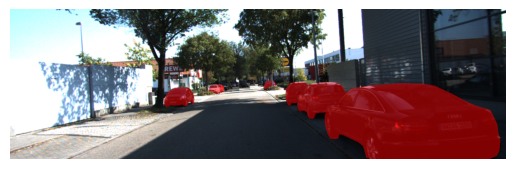

In [6]:
example_seq = frames[frames["seq"] == INSTANCE]
row = example_seq.iloc[0]
img = cv2.imread(row["image_path"])
gt = mask.decode(row["gt_object"]).astype(bool)
ignore = mask.decode(row["ignore_object"]).astype(bool)

plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.imshow(np.ma.masked_where(~ignore, ignore), cmap="gray", alpha=0.5)
plt.imshow(np.ma.masked_where(~gt, gt), cmap="autumn", alpha=0.5)
plt.axis("off")


# Baselines

## Classes description

We use pretrained YOLO model on COCO dataset. COCO dataset has 80 classes where some of the classes match with ours. 

0: person
2: car
3: motorcycle
5: bus
7: truck

The number before the it's ID of it, so when the model will output 0, we will be mapping it to equivavalent class 2 in our dataset.

After I looked at KITTI data more thoroughly, I find out that there annotated only usual vehicles. So other classes other then car and pereson are not actaully usefull for this expirement.

In [18]:
classes_map = {
    0: 2,
    2: 1
}

In [8]:
torch.cuda.is_available()

True

In [ ]:
def iou(pred, gt, ignore):
    valid = ~ignore
    intersection = (pred & gt & valid).sum()
    union = ((pred | gt) & valid).sum()
    return intersection, union


def to_mask(rle, shape):
    if isinstance(rle, dict):
        return mask.decode(rle).astype(bool)
    return np.zeros(shape, dtype=bool)


def to_rle(m):
    return mask.encode(np.asfortranarray(m.astype(np.uint8)))


def segment(model, img):
    result = model.predict(img, classes=list(classes_map), retina_masks=True, verbose=False)[0]
    if result.masks is None:
        return np.zeros(img.shape[:2], dtype=bool)
    return result.masks.data.any(dim=0).cpu().numpy().astype(bool)


def error_overlay(img, pred, gt, ignore):
    """Green: correct, red: false positive, blue: missed, yellow: ignored. Returns a BGR image."""
    vis = img.copy()
    valid = ~ignore
    layers = [
        (pred & gt & valid, (0, 255, 0)),
        (pred & ~gt & valid, (0, 0, 255)),
        (~pred & gt & valid, (255, 0, 0)),
        (ignore, (0, 255, 255)),
    ]
    for m, colour in layers:
        vis[m] = 0.5 * vis[m] + 0.5 * np.array(colour)
    return vis



def run_sequence(seq_frames, model, interval=1, propagate=None):
    """Segment every `interval` frames. In between propogate mask or hold it"""
    rows = []
    pred = prev_img = None
    for i, row in enumerate(seq_frames.sort_values("time_frame").itertuples()):
        img = cv2.imread(row.image_path)
        shape = img.shape[:2]
        mask_age = i % interval

        t0 = time.perf_counter()
        if mask_age == 0:
            pred = segment(model, img)
        elif propagate is not None:
            pred = propagate(pred, prev_img, img)
        step_time = time.perf_counter() - t0
        prev_img = img

        intersection, union = iou(pred, to_mask(row.gt_object, shape), to_mask(row.ignore_object, shape))
        rows.append({
            "seq": row.seq,
            "time_frame": row.time_frame,
            "mask_age": mask_age,
            "intersection": intersection,
            "union": union,
            "step_time": step_time,
            "pred_rle": to_rle(pred),
        })
    return pd.DataFrame(rows)

## Baseline 1: segmentation on every frame

In [26]:
model = YOLO("yolo26m-seg.pt", task='segment')
segment(model, cv2.imread(frames["image_path"].iloc[0]))  # warm-up, so the first timed frame is not an outlier

results = pd.concat([run_sequence(g, model) for _, g in frames.groupby("seq")], ignore_index=True)

In [27]:
def score_frames(results, frames):
    return (results[results["union"] > 0].merge(frames, on=KEYS)
            .assign(iou=lambda d: d["intersection"] / d["union"])
            .sort_values("iou"))


def show_frames(rows):
    fig, axes = plt.subplots(len(rows), 1, figsize=(12, 4 * len(rows)), squeeze=False)
    for ax, row in zip(axes[:, 0], rows.itertuples()):
        img = cv2.imread(row.image_path)
        shape = img.shape[:2]
        overlay = error_overlay(img, to_mask(row.pred_rle, shape), to_mask(row.gt_object, shape), to_mask(row.ignore_object, shape))
        ax.imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
        ax.set_title(f"seq {row.seq}, frame {row.time_frame}, IoU {row.iou:.2f}")
        ax.axis("off")
    fig.legend(
        handles=[Patch(color="green", label="correct"),
                 Patch(color="red", label="false positive"),
                 Patch(color="blue", label="missed"),
                 Patch(color="yellow", label="ignored")],
        loc="lower center", ncol=3,
    )

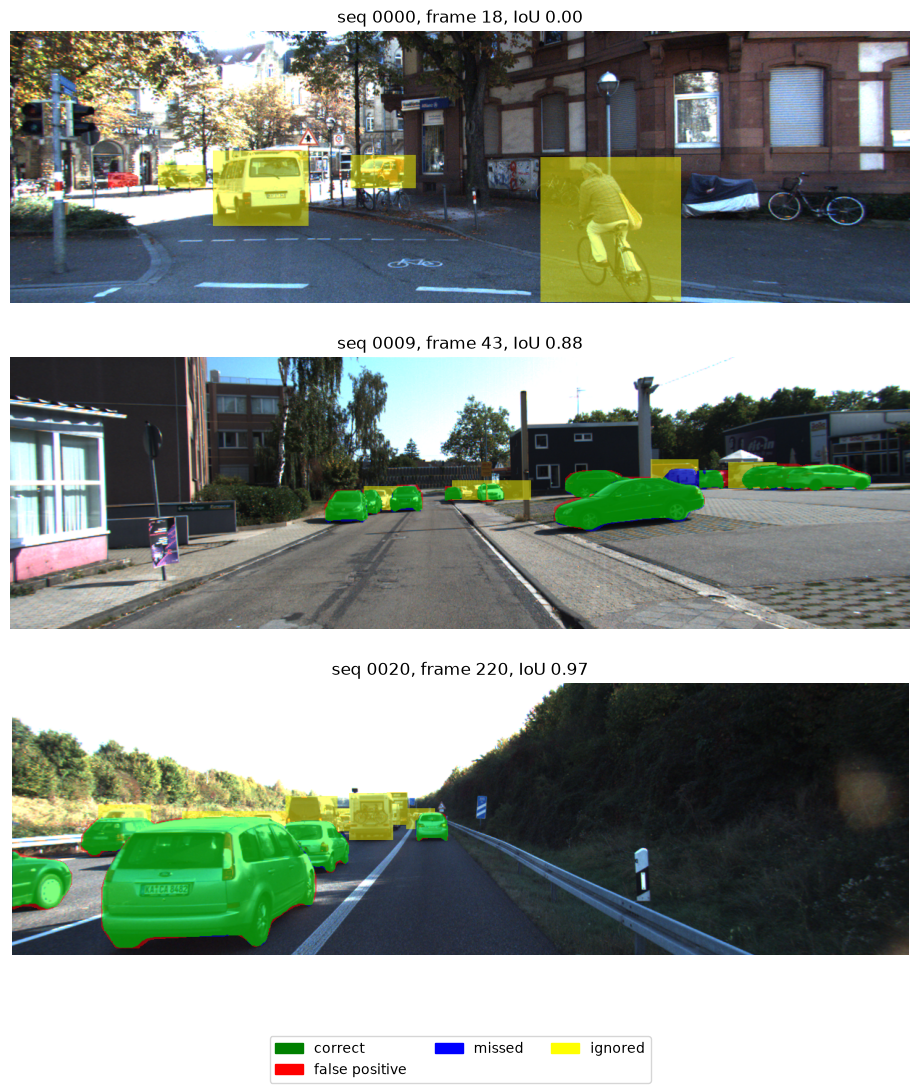

In [28]:
scored = score_frames(results, frames)
show_frames(scored.iloc[[0, len(scored) // 2, -1]])

In [29]:
results

,seq,time_frame,mask_age,intersection,union,step_time,pred_rle
0,0000,0,0,4684,5962,0.075981,"{'size': [375, 1242], 'counts': b'So\\3g0P;001..."
1,0000,1,0,4913,5898,0.071788,"{'size': [375, 1242], 'counts': b'QR^3f1P:4M1N..."
2,0000,2,0,5550,6168,0.064495,"{'size': [375, 1242], 'counts': b'df]3X1X:7J7K..."
3,0000,3,0,4036,4544,0.037767,"{'size': [375, 1242], 'counts': b'WdV1`0V;100O..."
4,0000,4,0,755,1666,0.035373,"{'size': [375, 1242], 'counts': b'jVQ3m0j:0000..."
...,...,...,...,...,...,...,...
5022,0020,832,0,22623,24627,0.015245,"{'size': [376, 1241], 'counts': b'Wf^3=Y;3O1O2..."
5023,0020,833,0,22595,24043,0.014666,"{'size': [376, 1241], 'counts': b'Vf^3>Y;2O1O1..."
5024,0020,834,0,22441,23784,0.014841,"{'size': [376, 1241], 'counts': b'Uf^3?Y;1O1O1..."
5025,0020,835,0,22299,23731,0.015413,"{'size': [376, 1241], 'counts': b'mQ_3`0X;1O1O..."
